In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()


Saving Online Retail.xlsx to Online Retail.xlsx


In [2]:

df = pd.read_excel("Online Retail.xlsx", engine="openpyxl")

# Remove exact duplicate rows, following Day 6
df_clean = df.drop_duplicates().copy()

# Convert transaction date to datetime
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)

print("Original dataset:", df.shape)
print("After exact duplicate removal:", df_clean.shape)

display(df_clean.head())


Original dataset: (541909, 8)
After exact duplicate removal: (536641, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:

print("Price statistics:")
display(df_clean["UnitPrice"].describe())

print("Quantity statistics:")
display(df_clean["Quantity"].describe())

print("Number of unique products:", df_clean["StockCode"].nunique())
print("Number of countries:", df_clean["Country"].nunique())
print("Date range:",
      df_clean["InvoiceDate"].min(),
      "to",
      df_clean["InvoiceDate"].max())


Price statistics:


,UnitPrice
count,536641.000000
mean,4.632656
std,97.233118
min,-11062.060000
25%,1.250000
50%,2.080000
75%,4.130000
max,38970.000000


Quantity statistics:


,Quantity
count,536641.000000
mean,9.620029
std,219.130156
min,-80995.000000
25%,1.000000
50%,3.000000
75%,10.000000
max,80995.000000


Number of unique products: 4070
Number of countries: 38
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


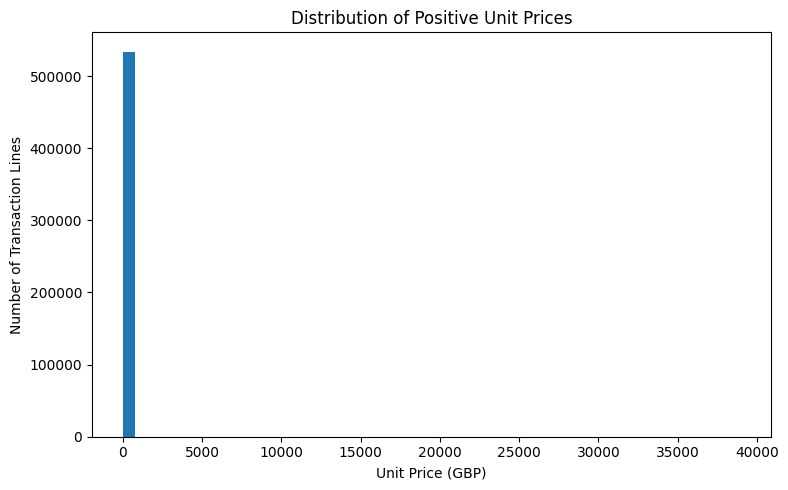

In [4]:

# Positive prices only for this distribution plot
prices = df_clean.loc[df_clean["UnitPrice"] > 0, "UnitPrice"]

plt.figure(figsize=(8, 5))
plt.hist(prices, bins=50)
plt.xlabel("Unit Price (GBP)")
plt.ylabel("Number of Transaction Lines")
plt.title("Distribution of Positive Unit Prices")
plt.tight_layout()
plt.show()


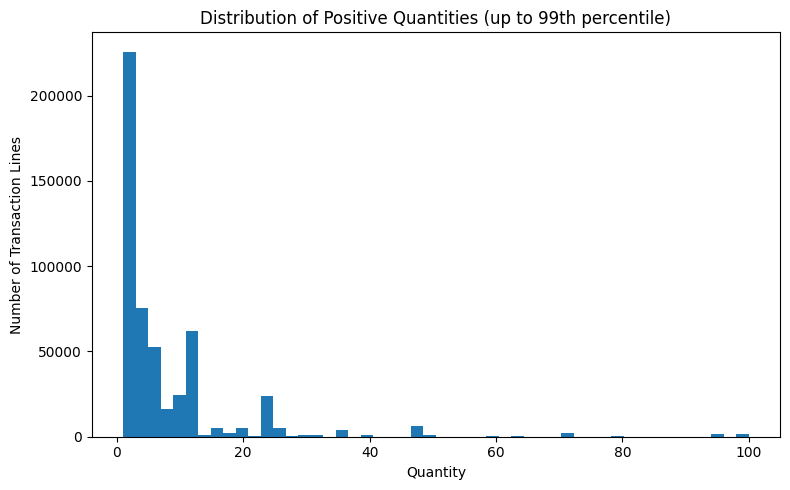

In [5]:

# Positive quantities only for this plot
quantities = df_clean.loc[
    df_clean["Quantity"] > 0, "Quantity"
]

plt.figure(figsize=(8, 5))
plt.hist(quantities[quantities <= quantities.quantile(0.99)], bins=50)
plt.xlabel("Quantity")
plt.ylabel("Number of Transaction Lines")
plt.title("Distribution of Positive Quantities (up to 99th percentile)")
plt.tight_layout()
plt.show()


,Month,LineRevenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


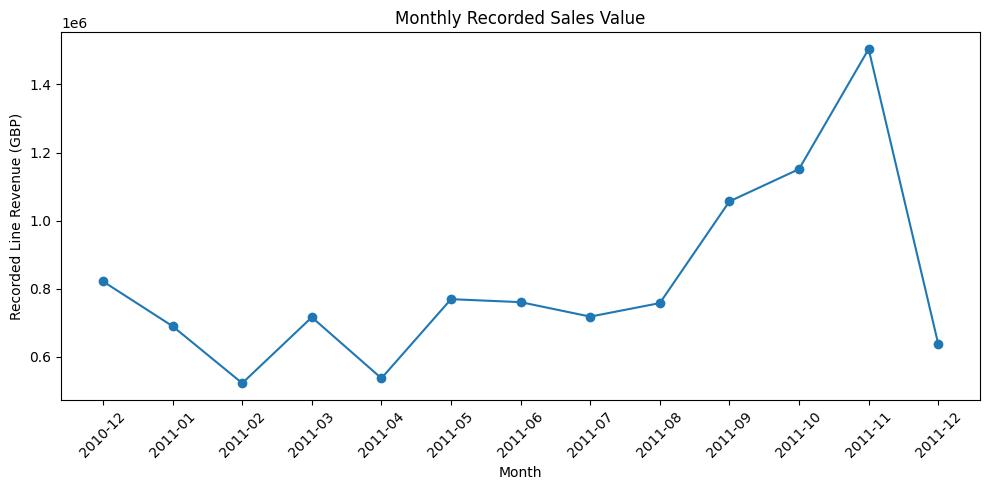

In [6]:

# Use positive-quantity, positive-price lines for this
# preliminary descriptive revenue view.
sales_data = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0) &
    (df_clean["InvoiceDate"].notna())
].copy()

sales_data["LineRevenue"] = (
    sales_data["Quantity"] * sales_data["UnitPrice"]
)

sales_data["Month"] = (
    sales_data["InvoiceDate"].dt.to_period("M").astype(str)
)

monthly_sales = (
    sales_data.groupby("Month", as_index=False)["LineRevenue"]
    .sum()
)

display(monthly_sales)

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales["Month"], monthly_sales["LineRevenue"], marker="o")
plt.xlabel("Month")
plt.ylabel("Recorded Line Revenue (GBP)")
plt.title("Monthly Recorded Sales Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [7]:

from pathlib import Path

Path("reports").mkdir(exist_ok=True)

eda_summary = pd.DataFrame({
    "Metric": [
        "Rows after exact duplicate removal",
        "Unique products",
        "Countries",
        "Positive price transaction lines",
        "Positive quantity transaction lines",
        "Months represented in preliminary sales view"
    ],
    "Value": [
        len(df_clean),
        df_clean["StockCode"].nunique(),
        df_clean["Country"].nunique(),
        int((df_clean["UnitPrice"] > 0).sum()),
        int((df_clean["Quantity"] > 0).sum()),
        len(monthly_sales)
    ]
})

display(eda_summary)

eda_summary.to_csv("reports/day7_eda_summary.csv", index=False)
print("EDA summary saved.")


,Metric,Value
0,Rows after exact duplicate removal,536641
1,Unique products,4070
2,Countries,38
3,Positive price transaction lines,534129
4,Positive quantity transaction lines,526054
5,Months represented in preliminary sales view,13


EDA summary saved.
